# HDFC Bank - Loan Approval Prediction System
### Artificial Intelligence & Machine Learning Project
**Problem Statement:** Develop a supervised machine learning classification model to predict whether a loan application should be **Approved** or **Rejected** based on applicant details (income, loan amount, credit history, employment status, assets, etc.).

---

### Project Workflow:
1. **Load Data & Inspect**
2. **Data Cleaning & Handling Anomalies**
3. **Exploratory Data Analysis (EDA)**
4. **Train-Test Split**
5. **Model Training (Logistic Regression, Decision Tree, Random Forest)**
6. **Model Evaluation & Comparison**
7. **Feature Importance**
8. **Predict for a New Loan Applicant**


## Step 1: Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Plot styling
plt.style.use('ggplot')
print("Libraries imported successfully!")


Libraries imported successfully!


## Step 2: Load Data & Clean
We load `loan_approval_dataset.csv`. We strip any leading/trailing spaces from column names and string values, and handle negative asset values.

In [2]:
# Load CSV file
df = pd.read_csv('loan_approval_dataset.csv')

# Clean column names (strip whitespace)
df.columns = df.columns.str.strip()

# Clean categorical text columns (strip whitespace)
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Drop loan_id (it is just an ID number, not a predictive feature)
if 'loan_id' in df.columns:
    df = df.drop(columns=['loan_id'])

# Fix negative values in residential assets (clip to 0)
df['residential_assets_value'] = df['residential_assets_value'].clip(lower=0)

print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
df.head()


Dataset Shape: (4269, 12)

Missing Values:
 no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


C:\Users\harsh\AppData\Local\Temp\ipykernel_12488\3641906650.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Step 3: Exploratory Data Analysis (EDA)
Let us understand the distribution of approved vs rejected loans and the impact of CIBIL credit score.

C:\Users\harsh\AppData\Local\Temp\ipykernel_12488\228546179.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='loan_status', data=df, palette=['#2ecc71', '#e74c3c'])
C:\Users\harsh\AppData\Local\Temp\ipykernel_12488\228546179.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status', y='cibil_score', data=df, palette=['#2ecc71', '#e74c3c'])


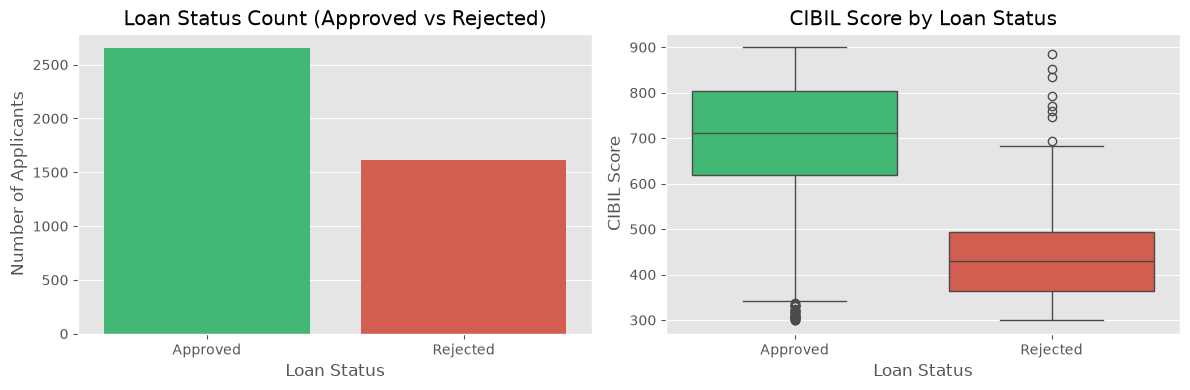

Approval Rate:
loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(12, 4))

# 1. Target distribution
plt.subplot(1, 2, 1)
sns.countplot(x='loan_status', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Loan Status Count (Approved vs Rejected)')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')

# 2. CIBIL score vs Loan Status
plt.subplot(1, 2, 2)
sns.boxplot(x='loan_status', y='cibil_score', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('CIBIL Score by Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('CIBIL Score')

plt.tight_layout()
plt.show()

print("Approval Rate:")
print(df['loan_status'].value_counts(normalize=True) * 100)


## Step 4: Data Preprocessing & Train-Test Split
We convert categorical variables (`education`, `self_employed`, `loan_status`) into numbers (0 and 1) and split into **80% training** and **20% testing** sets.

In [4]:
# Encode categorical columns
df['education'] = df['education'].map({'Graduate': 1, 'Not Graduate': 0})
df['self_employed'] = df['self_employed'].map({'Yes': 1, 'No': 0})
df['loan_status'] = df['loan_status'].map({'Approved': 1, 'Rejected': 0})

# Features (X) and Target (y)
X = df.drop(columns=['loan_status'])
y = df['loan_status']

# Split 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")


Training samples: 3415
Testing samples: 854


## Step 5: Train Supervised Machine Learning Models
We train three classic classification models:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**

In [5]:
# 1. Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 2. Decision Tree
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

# 3. Random Forest
rf_model = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

print("All 3 models trained successfully!")


All 3 models trained successfully!


## Step 6: Model Evaluation & Comparison
We evaluate the performance of each model on the holdout test set using **Accuracy**, **Confusion Matrix**, and **Classification Report**.

In [6]:
# Make predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# Compare Accuracies
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ]
})

print("=== Model Comparison ===")
print(results.to_string(index=False))

# Classification Report for Best Model (Random Forest)
print("\n=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=['Rejected', 'Approved']))


=== Model Comparison ===
              Model  Test Accuracy
Logistic Regression       0.913349
      Decision Tree       0.969555
      Random Forest       0.978923

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    Rejected       0.98      0.97      0.97       323
    Approved       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



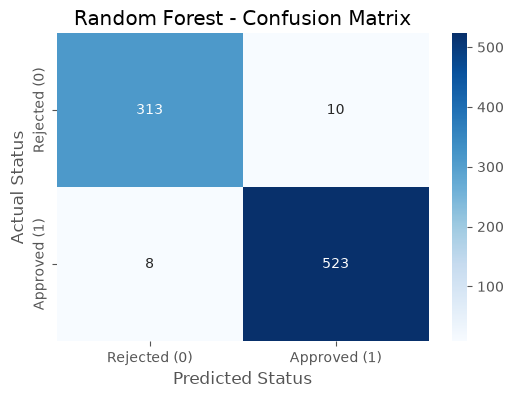

In [7]:
# Plot Confusion Matrix for Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected (0)', 'Approved (1)'],
            yticklabels=['Rejected (0)', 'Approved (1)'])
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Status')
plt.ylabel('Actual Status')
plt.show()


## Step 7: Feature Importance
Which factors are most important in deciding whether HDFC Bank approves a loan?
We examine the feature importances from our Random Forest model.

C:\Users\harsh\AppData\Local\Temp\ipykernel_12488\4219421966.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='Blues_r')


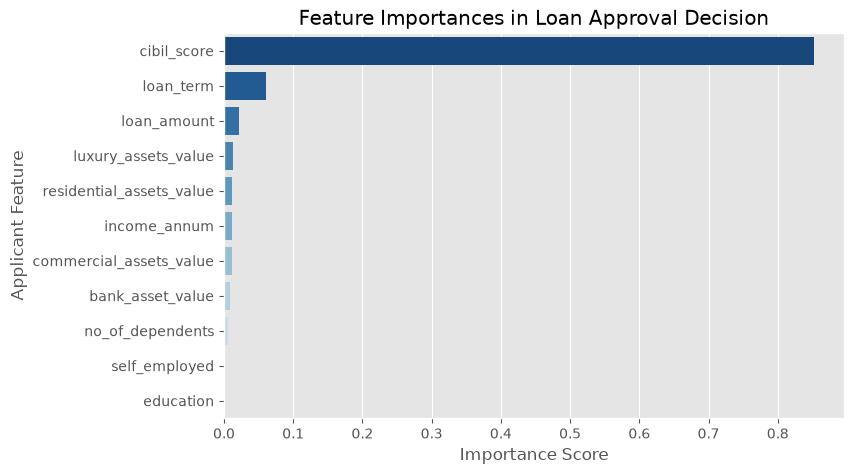

Ranked Features:
                 Feature  Importance
             cibil_score    0.852971
               loan_term    0.060051
             loan_amount    0.022016
     luxury_assets_value    0.012851
residential_assets_value    0.012042
            income_annum    0.011314
 commercial_assets_value    0.011113
        bank_asset_value    0.008862
        no_of_dependents    0.005617
           self_employed    0.001861
               education    0.001302


In [8]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='Blues_r')
plt.title('Feature Importances in Loan Approval Decision')
plt.xlabel('Importance Score')
plt.ylabel('Applicant Feature')
plt.show()

print("Ranked Features:")
print(importance_df.to_string(index=False))


## Step 8: Predict Loan Status for a New Applicant
Let's test our trained model on a new applicant profile to see whether HDFC Bank approves or rejects the application!

In [9]:
def predict_loan(applicant_dict):
    """Predicts loan status for a single applicant dictionary."""
    input_df = pd.DataFrame([applicant_dict])
    prediction = rf_model.predict(input_df)[0]
    probability = rf_model.predict_proba(input_df)[0][1]
    
    status = "APPROVED" if prediction == 1 else "REJECTED"
    print(f"Decision: {status}")
    print(f"Approval Probability: {probability:.1%}")
    return status

# Example Applicant
sample_applicant = {
    'no_of_dependents': 2,
    'education': 1,           # 1 = Graduate
    'self_employed': 0,       # 0 = Salaried
    'income_annum': 7500000,   # Rs. 75,00,000
    'loan_amount': 15000000,   # Rs. 1,50,00,000
    'loan_term': 10,          # 10 years
    'cibil_score': 780,        # Excellent CIBIL score
    'residential_assets_value': 8000000,
    'commercial_assets_value': 3000000,
    'luxury_assets_value': 12000000,
    'bank_asset_value': 5000000
}

print("Testing Sample Applicant:")
predict_loan(sample_applicant)


Testing Sample Applicant:
Decision: APPROVED
Approval Probability: 98.1%


'APPROVED'